<a href="https://colab.research.google.com/github/ReetomGogoi/GhostVision-AI/blob/feature%2Fthermal/GhostVision_Thermal_Nikhil.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:

import os
import shutil

print("Colab is ready!")
print("Available disk space:", round(shutil.disk_usage("/content").free / 1e9, 2), "GB")
print("GPU check:")
!nvidia-smi


Colab is ready!
Available disk space: 75.46 GB
GPU check:
Fri Oct 23 13:54:04 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   64C    P8             12W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |              

In [1]:

import torch

print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
else:
    print("GPU not connected")


GPU Available: True
GPU Name: Tesla T4


In [4]:

import os

os.makedirs("/content/thermal_data", exist_ok=True)
os.chdir("/content/thermal_data")

!wget -c --progress=bar:force \
"https://zenodo.org/records/15773102/files/bambi-bounding_box-20250523.v1i.yolov12.zip?download=1" \
-O bambi.zip

if os.path.exists("bambi.zip"):
    print("Downloaded size:",
          round(os.path.getsize("bambi.zip") / 1e9, 2),
          "GB")


--2026-10-23 14:59:51--  https://zenodo.org/records/15773102/files/bambi-bounding_box-20250523.v1i.yolov12.zip?download=1
Resolving zenodo.org (zenodo.org)... 188.185.51.60, 137.138.121.78, 188.185.40.132, ...
Connecting to zenodo.org (zenodo.org)|188.185.51.60|:443... connected.
HTTP request sent, awaiting response... 416 REQUESTED_RANGE_NOT_SATISFIABLE

    The file is already fully retrieved; nothing to do.

Downloaded size: 9.44 GB


In [5]:

import os
import zipfile

zip_path = "/content/thermal_data/bambi.zip"
extract_path = "/content/thermal_data/bambi"

print("Checking dataset ZIP...")

if not zipfile.is_zipfile(zip_path):
    raise ValueError("Invalid ZIP file!")

with zipfile.ZipFile(zip_path, "r") as z:
    print("Files inside ZIP:", len(z.namelist()))
    print("Extracting dataset...")
    z.extractall(extract_path)

print("Extraction complete!")
print("Extracted folders:")
print(os.listdir(extract_path)[:20])


Checking dataset ZIP...
Files inside ZIP: 164356
Extracting dataset...
Extraction complete!
Extracted folders:
['README.roboflow.txt', 'valid', 'data.yaml', 'test', 'train', 'README.dataset.txt']


In [6]:

import os
import yaml

dataset_path = "/content/thermal_data/bambi"

# Read dataset configuration
with open(f"{dataset_path}/data.yaml", "r") as f:
    config = yaml.safe_load(f)

print("DATASET CONFIGURATION")
print(config)

print("\nDATASET SPLITS")

for split in ["train", "valid", "test"]:
    image_dir = f"{dataset_path}/{split}/images"
    label_dir = f"{dataset_path}/{split}/labels"

    images = os.listdir(image_dir) if os.path.isdir(image_dir) else []
    labels = os.listdir(label_dir) if os.path.isdir(label_dir) else []

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Labels:", len(labels))

print("\nANIMAL CLASSES:")
print(config.get("names"))


DATASET CONFIGURATION
{'train': '../train/images', 'val': '../valid/images', 'test': '../test/images', 'nc': 1, 'names': ['bambi_detect - v6 2025-05-22 2-22pm'], 'roboflow': {'workspace': 'dseducation', 'project': 'bambi-bounding_box-20250523', 'version': 1, 'license': 'CC BY 4.0', 'url': 'https://universe.roboflow.com/dseducation/bambi-bounding_box-20250523/dataset/1'}}

DATASET SPLITS

TRAIN
Images: 78650
Labels: 78650

VALID
Images: 1696
Labels: 1696

TEST
Images: 1826
Labels: 1826

ANIMAL CLASSES:
['bambi_detect - v6 2025-05-22 2-22pm']


Image: 0_7707_jpg.rf.a782601dee3a5cec889f4696784c8c73.jpg
Image dimensions: 1024 x 1024
Annotations: 0
Bounding boxes: []


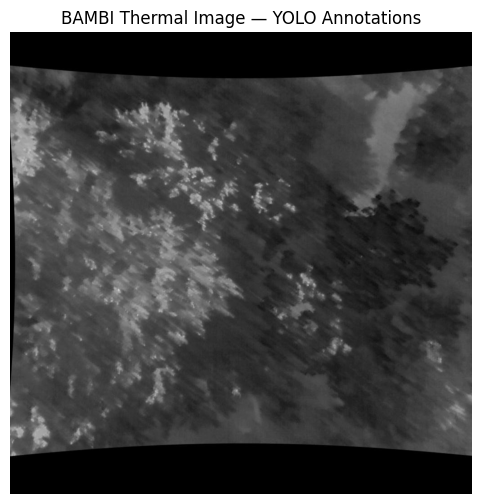

In [7]:

from pathlib import Path
import cv2
import matplotlib.pyplot as plt

dataset = Path("/content/thermal_data/bambi")
images = sorted((dataset / "train/images").glob("*"))
images = [p for p in images if p.suffix.lower() in
          [".jpg", ".jpeg", ".png"]]

img_path = images[0]
label_path = dataset / "train/labels" / (img_path.stem + ".txt")

img = cv2.imread(str(img_path))
if img is None:
    raise ValueError("Unable to read sample image")

h, w = img.shape[:2]
boxes = []

if label_path.exists():
    for line in label_path.read_text().splitlines():
        parts = line.split()
        if len(parts) != 5:
            continue
        cls, x, y, bw, bh = map(float, parts)
        x1 = int((x - bw / 2) * w)
        y1 = int((y - bh / 2) * h)
        x2 = int((x + bw / 2) * w)
        y2 = int((y + bh / 2) * h)
        boxes.append((int(cls), x1, y1, x2, y2))
        cv2.rectangle(img, (x1, y1), (x2, y2),
                      (0, 255, 0), 2)

print("Image:", img_path.name)
print("Image dimensions:", w, "x", h)
print("Annotations:", len(boxes))
print("Bounding boxes:", boxes[:5])

plt.figure(figsize=(9, 6))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("BAMBI Thermal Image — YOLO Annotations")
plt.show()


Image: 0_8083_jpg.rf.09e7a85491cdce4ffd720430fa111d51.jpg
Number of annotations: 1


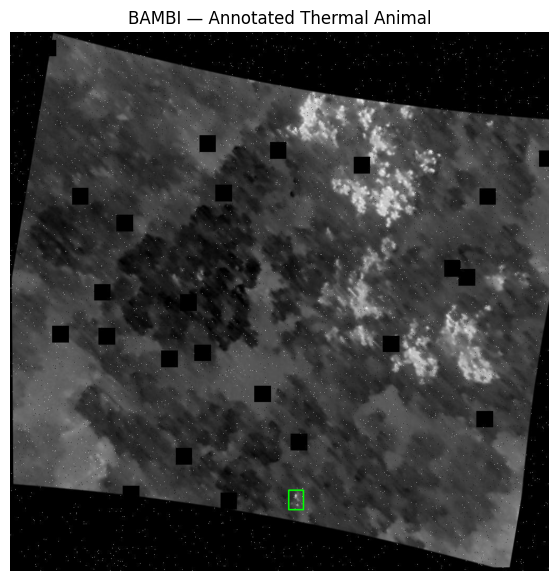

In [8]:

from pathlib import Path
import cv2
import matplotlib.pyplot as plt

dataset = Path("/content/thermal_data/bambi")

image_dir = dataset / "train/images"
label_dir = dataset / "train/labels"

found = False

for label_path in sorted(label_dir.glob("*.txt")):
    lines = label_path.read_text().strip().splitlines()

    if not lines:
        continue

    for ext in [".jpg", ".jpeg", ".png"]:
        img_path = image_dir / (label_path.stem + ext)
        if img_path.exists():
            found = True
            break

    if found:
        break

if not found:
    raise ValueError("No labeled animal images found!")

img = cv2.imread(str(img_path))
h, w = img.shape[:2]

for line in lines:
    values = line.split()

    if len(values) != 5:
        continue

    cls, x, y, bw, bh = map(float, values)

    x1 = int((x - bw / 2) * w)
    y1 = int((y - bh / 2) * h)
    x2 = int((x + bw / 2) * w)
    y2 = int((y + bh / 2) * h)

    cv2.rectangle(img, (x1, y1), (x2, y2),
                  (0, 255, 0), 2)

print("Image:", img_path.name)
print("Number of annotations:", len(lines))

plt.figure(figsize=(9, 7))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("BAMBI — Annotated Thermal Animal")
plt.axis("off")
plt.show()


In [9]:

from pathlib import Path
from collections import Counter

base = Path("/content/thermal_data/bambi")

for split in ["train", "valid", "test"]:
    labels = list((base / split / "labels").glob("*.txt"))

    positive = 0
    empty = 0
    invalid = 0
    total_boxes = 0

    for file in labels:
        lines = file.read_text().strip().splitlines()

        if not lines:
            empty += 1
            continue

        positive += 1

        for line in lines:
            try:
                values = list(map(float, line.split()))
                if len(values) != 5:
                    invalid += 1
                    continue

                cls, x, y, w, h = values

                if not (
                    cls == 0 and
                    0 <= x <= 1 and
                    0 <= y <= 1 and
                    0 < w <= 1 and
                    0 < h <= 1 and
                    x - w/2 >= -1e-5 and
                    y - h/2 >= -1e-5 and
                    x + w/2 <= 1 + 1e-5 and
                    y + h/2 <= 1 + 1e-5
                ):
                    invalid += 1

                total_boxes += 1

            except ValueError:
                invalid += 1

    print(f"\n{split.upper()}")
    print("Positive images:", positive)
    print("Empty images:", empty)
    print("Total boxes:", total_boxes)
    print("Invalid annotations:", invalid)



TRAIN
Positive images: 72707
Empty images: 5943
Total boxes: 221063
Invalid annotations: 0

VALID
Positive images: 1447
Empty images: 249
Total boxes: 9823
Invalid annotations: 0

TEST
Positive images: 1515
Empty images: 311
Total boxes: 4926
Invalid annotations: 0


In [10]:

%pip install -q ultralytics

from ultralytics import YOLO
import torch

model = YOLO("yolo11n.pt")

print("Model: YOLO11n")
print("GPU:", torch.cuda.get_device_name(0))
print("Number of detection classes:", len(model.names))
print("Model loaded successfully!")


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 81.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.2/98.2 kB 9.8 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Model: YOLO11n
GPU: Tesla T4
Number of detection classes: 80
Model loaded successfully!


In [11]:

from pathlib import Path
import yaml

base = Path("/content/thermal_data/bambi")

config = {
    "path": str(base),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": 1,
    "names": {0: "animal"}
}

config_path = base / "ghostvision_thermal.yaml"

with open(config_path, "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print("GhostVision thermal configuration created!")
print("Configuration path:", config_path)
print()
print(config_path.read_text())

for split in ["train", "valid", "test"]:
    assert (base / split / "images").is_dir()
    assert (base / split / "labels").is_dir()

print("All dataset folders verified!")


GhostVision thermal configuration created!
Configuration path: /content/thermal_data/bambi/ghostvision_thermal.yaml

path: /content/thermal_data/bambi
train: train/images
val: valid/images
test: test/images
nc: 1
names:
  0: animal

All dataset folders verified!


In [12]:

from pathlib import Path
from collections import defaultdict
import hashlib

base = Path("/content/thermal_data/bambi")
hashes = defaultdict(set)
counts = {"train": 0, "valid": 0, "test": 0}

for split in ["train", "valid", "test"]:
    folder = base / split / "images"

    for file in folder.iterdir():
        if file.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
            continue

        h = hashlib.sha256()

        with open(file, "rb") as f:
            for chunk in iter(lambda: f.read(1024 * 1024), b""):
                h.update(chunk)

        hashes[split].add(h.hexdigest())
        counts[split] += 1

    print(f"{split}: {counts[split]} images hashed")

print("\nEXACT DUPLICATES BETWEEN SPLITS")

for a, b in [
    ("train", "valid"),
    ("train", "test"),
    ("valid", "test")
]:
    overlap = len(hashes[a] & hashes[b])
    print(f"{a} vs {b}: {overlap}")


train: 78650 images hashed
valid: 1696 images hashed
test: 1826 images hashed

EXACT DUPLICATES BETWEEN SPLITS
train vs valid: 0
train vs test: 0
valid vs test: 0


In [13]:

from pathlib import Path
import random
import shutil
import yaml

source = Path("/content/thermal_data/bambi")
pilot = Path("/content/thermal_data/pilot")
rng = random.Random(42)

def prepare_split(split, amount):
    src_images = source / split / "images"
    src_labels = source / split / "labels"

    dst_images = pilot / split / "images"
    dst_labels = pilot / split / "labels"

    dst_images.mkdir(parents=True, exist_ok=True)
    dst_labels.mkdir(parents=True, exist_ok=True)

    positive = []
    negative = []

    for img in src_images.iterdir():
        if img.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
            continue

        label = src_labels / (img.stem + ".txt")

        if not label.exists():
            continue

        if label.stat().st_size > 0:
            positive.append(img)
        else:
            negative.append(img)

    rng.shuffle(positive)
    rng.shuffle(negative)

    n_negative = min(round(amount * 0.15), len(negative))
    selected = positive[:amount - n_negative]
    selected += negative[:n_negative]
    rng.shuffle(selected)

    for img in selected:
        shutil.copy2(img, dst_images / img.name)
        label = src_labels / (img.stem + ".txt")
        shutil.copy2(label, dst_labels / label.name)

    print(split, ":", len(selected), "images",
          "| positive:", len(selected) - n_negative,
          "| negative:", n_negative)

prepare_split("train", 2000)
prepare_split("valid", 300)

pilot_config = {
    "path": str(pilot),
    "train": "train/images",
    "val": "valid/images",
    "nc": 1,
    "names": {0: "animal"}
}

with open(pilot / "data.yaml", "w") as f:
    yaml.safe_dump(pilot_config, f, sort_keys=False)

print("\nPilot dataset prepared!")
print("Configuration:", pilot / "data.yaml")


train : 2000 images | positive: 1700 | negative: 300
valid : 300 images | positive: 255 | negative: 45

Pilot dataset prepared!
Configuration: /content/thermal_data/pilot/data.yaml


In [14]:

from ultralytics import YOLO
import torch

assert torch.cuda.is_available(), "GPU not connected!"

# Load pretrained YOLO11n
model = YOLO("yolo11n.pt")

# Train on the BAMBI thermal pilot dataset
results = model.train(
    data="/content/thermal_data/pilot/data.yaml",
    epochs=3,
    imgsz=640,
    batch=8,
    device=0,
    workers=2,
    project="/content/thermal_runs",
    name="yolo11n_pilot_v1",
    seed=42,
    plots=True
)

print("Pilot training completed!")
print("Results saved in:", model.trainer.save_dir)


Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/thermal_data/pilot/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=3, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11n_pilot_v1, nbs=64, nms=None, opset=None, optim

In [15]:

from google.colab import drive
from pathlib import Path
import shutil
import hashlib
import json

drive.mount("/content/drive")

source = Path(
    "/content/thermal_runs/yolo11n_pilot_v1"
)

backup = Path(
    "/content/drive/MyDrive/GhostVision-AI/"
    "thermal/yolo11n_pilot_v1"
)

backup.mkdir(parents=True, exist_ok=True)

files = [
    "weights/best.pt",
    "weights/last.pt",
    "results.csv",
    "args.yaml"
]

for filename in files:
    src = source / filename
    dst = backup / filename

    if not src.exists():
        print("Missing:", filename)
        continue

    dst.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(src, dst)

    def checksum(path):
        h = hashlib.sha256()
        with open(path, "rb") as f:
            for chunk in iter(
                lambda: f.read(1024 * 1024),
                b""
            ):
                h.update(chunk)
        return h.hexdigest()

    assert checksum(src) == checksum(dst)
    print("Verified backup:", filename)

print("\nModel backup location:", backup)
print("Backup complete!")


Mounted at /content/drive
Verified backup: weights/best.pt
Verified backup: weights/last.pt
Verified backup: results.csv
Verified backup: args.yaml

Model backup location: /content/drive/MyDrive/GhostVision-AI/thermal/yolo11n_pilot_v1
Backup complete!
